In [1]:
%pip install pandas numpy matplotlib tifffile scipy readlif

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---- ----------------------------------- 4.5/37.4 MB 21.1 MB/s eta 0:00:02
   ----------- ---------------------------- 10.7/37.4 MB 25.8 MB/s eta 0:00:02
   -------------------- ------------------- 19.1/37.4 MB 30.4 MB/s eta 0:00:01
   ----------------------------- ---------- 27.8/37.4 MB 33.1 MB/s eta 0:00:01
   ---------------------------------------  37.0/37.4 MB 35.4 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 31.8 MB/s  0:00:01

   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   -------- ------------------------------- 1/5 [soupsieve]
   ---------------- ----------------------- 2/5 [scipy]
   ---------------- ----------------------- 2/5 [scipy]
   ---------------- ----------------------- 2/5 [scipy]
   ---------------- ----------------------- 2/5 [scipy]
   ---------------- ----------------------- 2/5 [scipy]
 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from IPython.display import display

# Find the project root from the notebook's working directory.
ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "Images").is_dir()
        and (folder / "Person2_ROI_Orientation").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Replace ROOT with your full project path."
    )

# Existing inputs.
SOURCE = ROOT / "datasets" / "ventricular data"
MASK_DIR = SOURCE / "Masks"
P1_TABLES = ROOT / "Images" / "outputs" / "tables"
P2_HANDOFF = ROOT / "Person2_ROI_Orientation" / "Person3_Handoff"

# Your outputs.
P3 = ROOT / "Person3_Masks_Fibrosis"

TABLES = P3 / "data" / "processed"
DOCS = P3 / "docs"
FIGURES = P3 / "outputs" / "figures"
OVERLAYS = P3 / "outputs" / "mask_overlays"
ANALYSIS_MASKS = P3 / "outputs" / "analysis_masks"

for folder in [TABLES, DOCS, FIGURES, OVERLAYS, ANALYSIS_MASKS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Masks folder:", MASK_DIR)
print("Output tables:", TABLES)

if not MASK_DIR.is_dir():
    raise FileNotFoundError(f"Mask folder not found: {MASK_DIR}")

Project root: c:\Users\mmsr4\D37-Semantic-Data-Lake
Masks folder: c:\Users\mmsr4\D37-Semantic-Data-Lake\datasets\ventricular data\Masks
Output tables: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed


In [3]:
required_files = {
    "Person 1 image inventory": P1_TABLES / "image_inventory.csv",
    "Person 1 channel information": P1_TABLES / "image_channels.csv",
    "Person 1 image quality": P1_TABLES / "image_quality.csv",
    "Person 2 transform manifest": P2_HANDOFF / "roi_transform_manifest.csv",
    "Person 2 ROI validation": P2_HANDOFF / "roi_validation.csv",
    "Person 2 preliminary review": P2_HANDOFF / "manual_roi_review_merged.csv",
    "Original MATLAB script": SOURCE / "fibrosisAnalysis.m",
    "Original README": SOURCE / "sankarankutty_readme_20210921.txt",
}

file_check = pd.DataFrame([
    {
        "input": name,
        "exists": path.is_file(),
        "relative_path": str(path.relative_to(ROOT)),
    }
    for name, path in required_files.items()
])

display(file_check)

# Ignore Mac metadata files if any came with the download.
mask_files = sorted(
    path
    for path in MASK_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".tif", ".tiff"}
    and not path.name.startswith("._")
    and "__MACOSX" not in path.parts
)

print(f"\nTIFF masks found: {len(mask_files)} (expected: 13)")

for path in mask_files:
    print(path.relative_to(MASK_DIR))

if not mask_files:
    raise FileNotFoundError(
        "No TIFF masks found. Check the Masks folder and extraction."
    )

if len(mask_files) != 13:
    print("\nCHECK: The mask count differs from the expected 13.")

,input,exists,relative_path
0,Person 1 image inventory,True,Images\outputs\tables\image_inventory.csv
1,Person 1 channel information,True,Images\outputs\tables\image_channels.csv
2,Person 1 image quality,True,Images\outputs\tables\image_quality.csv
3,Person 2 transform manifest,True,Person2_ROI_Orientation\Person3_Handoff\roi_tr...
4,Person 2 ROI validation,True,Person2_ROI_Orientation\Person3_Handoff\roi_va...
5,Person 2 preliminary review,True,Person2_ROI_Orientation\Person3_Handoff\manual...
6,Original MATLAB script,True,datasets\ventricular data\fibrosisAnalysis.m
7,Original README,True,datasets\ventricular data\sankarankutty_readme...



TIFF masks found: 13 (expected: 13)
190930_1_Mask.tif
191007_1_Mask.tif
191017_1_Mask.tif
191017_5_Mask.tif
191101_1_Mask.tif
191108_1_Mask.tif
191210_4_Mask.tif
191211_3_Mask.tif
200102_1_Mask.tif
200106_2_Mask.tif
200214_1_Mask.tif
200219_1_Mask.tif
200318_2_Mask.tif


In [4]:
mask_rows = []

for path in mask_files:
    record = {
        "mask_filename": path.name,
        "mask_relative_path": str(path.relative_to(ROOT)),
        "sample_id": None,
        "loads_successfully": False,
        "shape": None,
        "ndim": None,
        "height_px": None,
        "width_px": None,
        "dtype": None,
        "tiff_page_count": None,
        "unique_value_count": None,
        "unique_values_preview": None,
        "total_array_elements": None,
        "zero_elements": None,
        "one_elements": None,
        "nonzero_elements": None,
        "all_values_same": None,
        "review_notes": "",
    }

    notes = []

    # Example: 190930_1_Mask.tif -> 190930_1_overview
    if path.stem.lower().endswith("_mask"):
        record["sample_id"] = path.stem[:-5] + "_overview"
    else:
        notes.append("Unexpected filename; sample mapping needs review.")

    try:
        with tifffile.TiffFile(path) as tif:
            record["tiff_page_count"] = len(tif.pages)
            mask = tif.asarray()

        values = np.unique(mask)

        record.update({
            "loads_successfully": True,
            "shape": str(mask.shape),
            "ndim": mask.ndim,
            "dtype": str(mask.dtype),
            "unique_value_count": len(values),
            "unique_values_preview": str(values[:20].tolist()),
            "total_array_elements": int(mask.size),
            "zero_elements": int(np.count_nonzero(mask == 0)),
            "one_elements": int(np.count_nonzero(mask == 1)),
            "nonzero_elements": int(np.count_nonzero(mask)),
            "all_values_same": len(values) == 1,
        })

        if mask.ndim == 2:
            record["height_px"], record["width_px"] = mask.shape
        else:
            notes.append("Not a 2D mask; inspect before calculating coverage.")

        if not np.isfinite(mask).all():
            notes.append("Contains non-finite values.")

        if len(values) == 1:
            notes.append(
                "Constant-valued mask; confirm whether this is intentional."
            )

        if len(values) > 2:
            notes.append(
                "More than two stored values; verify mask encoding."
            )

        del mask

    except Exception as exc:
        notes.append(f"Read failed: {type(exc).__name__}: {exc}")

    record["review_notes"] = " | ".join(notes)
    mask_rows.append(record)

mask_inventory = pd.DataFrame(mask_rows)

inventory_path = TABLES / "mask_inventory.csv"
mask_inventory.to_csv(inventory_path, index=False)

display(mask_inventory)

print("\nMasks inspected:", len(mask_inventory))
print("Successfully loaded:", mask_inventory["loads_successfully"].sum())
print("Saved to:", inventory_path)

,mask_filename,mask_relative_path,sample_id,loads_successfully,shape,ndim,height_px,width_px,dtype,tiff_page_count,unique_value_count,unique_values_preview,total_array_elements,zero_elements,one_elements,nonzero_elements,all_values_same,review_notes
0,190930_1_Mask.tif,datasets\ventricular data\Masks\190930_1_Mask.tif,190930_1_overview,True,"(1583, 4628)",2,1583,4628,uint8,1,2,"[0, 1]",7326124,3289693,4036431,4036431,False,
1,191007_1_Mask.tif,datasets\ventricular data\Masks\191007_1_Mask.tif,191007_1_overview,True,"(2640, 2640)",2,2640,2640,uint8,1,2,"[0, 255]",6969600,6357097,0,612503,False,
2,191017_1_Mask.tif,datasets\ventricular data\Masks\191017_1_Mask.tif,191017_1_overview,True,"(2648, 2644)",2,2648,2644,uint8,1,2,"[0, 1]",7001312,6520648,480664,480664,False,
3,191017_5_Mask.tif,datasets\ventricular data\Masks\191017_5_Mask.tif,191017_5_overview,True,"(2641, 2640)",2,2641,2640,uint8,1,2,"[0, 1]",6972240,6208250,763990,763990,False,
4,191101_1_Mask.tif,datasets\ventricular data\Masks\191101_1_Mask.tif,191101_1_overview,True,"(4882, 1321)",2,4882,1321,uint8,1,2,"[0, 1]",6449122,6097512,351610,351610,False,
5,191108_1_Mask.tif,datasets\ventricular data\Masks\191108_1_Mask.tif,191108_1_overview,True,"(2648, 2653)",2,2648,2653,uint8,1,2,"[0, 1]",7025144,4440297,2584847,2584847,False,
6,191210_4_Mask.tif,datasets\ventricular data\Masks\191210_4_Mask.tif,191210_4_overview,True,"(2640, 2640)",2,2640,2640,uint8,1,2,"[0, 1]",6969600,6166427,803173,803173,False,
7,191211_3_Mask.tif,datasets\ventricular data\Masks\191211_3_Mask.tif,191211_3_overview,True,"(2640, 2640)",2,2640,2640,uint8,1,2,"[0, 1]",6969600,2167855,4801745,4801745,False,
8,200102_1_Mask.tif,datasets\ventricular data\Masks\200102_1_Mask.tif,200102_1_overview,True,"(1856, 4240)",2,1856,4240,uint8,1,2,"[0, 1]",7869440,7064966,804474,804474,False,
9,200106_2_Mask.tif,datasets\ventricular data\Masks\200106_2_Mask.tif,200106_2_overview,True,"(2640, 2640)",2,2640,2640,uint8,1,2,"[0, 1]",6969600,5327010,1642590,1642590,False,



Masks inspected: 13
Successfully loaded: 13
Saved to: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\mask_inventory.csv


In [5]:
summary_columns = [
    "sample_id",
    "mask_filename",
    "loads_successfully",
    "height_px",
    "width_px",
    "dtype",
    "unique_values_preview",
    "review_notes",
]

display(mask_inventory[summary_columns])

duplicate_ids = mask_inventory.loc[
    mask_inventory["sample_id"].notna()
    & mask_inventory["sample_id"].duplicated(keep=False)
]

if duplicate_ids.empty:
    print("No duplicate mask sample IDs found.")
else:
    print("CHECK: Duplicate mask sample IDs found:")
    display(duplicate_ids[["sample_id", "mask_relative_path"]])

failed_masks = mask_inventory.loc[
    ~mask_inventory["loads_successfully"]
]

print("\nFailed mask reads:", len(failed_masks))

print(
    "\nInventory complete. Foreground interpretation and "
    "image alignment have not yet been validated."
)

,sample_id,mask_filename,loads_successfully,height_px,width_px,dtype,unique_values_preview,review_notes
0,190930_1_overview,190930_1_Mask.tif,True,1583,4628,uint8,"[0, 1]",
1,191007_1_overview,191007_1_Mask.tif,True,2640,2640,uint8,"[0, 255]",
2,191017_1_overview,191017_1_Mask.tif,True,2648,2644,uint8,"[0, 1]",
3,191017_5_overview,191017_5_Mask.tif,True,2641,2640,uint8,"[0, 1]",
4,191101_1_overview,191101_1_Mask.tif,True,4882,1321,uint8,"[0, 1]",
5,191108_1_overview,191108_1_Mask.tif,True,2648,2653,uint8,"[0, 1]",
6,191210_4_overview,191210_4_Mask.tif,True,2640,2640,uint8,"[0, 1]",
7,191211_3_overview,191211_3_Mask.tif,True,2640,2640,uint8,"[0, 1]",
8,200102_1_overview,200102_1_Mask.tif,True,1856,4240,uint8,"[0, 1]",
9,200106_2_overview,200106_2_Mask.tif,True,2640,2640,uint8,"[0, 1]",


No duplicate mask sample IDs found.

Failed mask reads: 0

Inventory complete. Foreground interpretation and image alignment have not yet been validated.


In [6]:
readme_path = SOURCE / "sankarankutty_readme_20210921.txt"

if not readme_path.exists():
    raise FileNotFoundError(f"README not found: {readme_path}")

readme_text = readme_path.read_text(
    encoding="utf-8",
    errors="replace"
)

print(readme_text)

This sankarankutty_readme_20210610.txt file was generated on 20210601 by Aparna C Sankarankutty
This README.txt file was edited on 20210921 by Tina Kirkham

------------------- GENERAL INFORMATION -------------------


1. Title of Dataset
Dataset for: Etiology-Specific Remodeling in Ventricular Tissue of Heart Failure Patients and its Implications for Computational Modeling of Electrical Conduction

2. Author Information

  Principal Investigator Contact Information 
  	Name: Frank Sachse 
  		Institution: University of Utah
  		Address: The Nora Eccles Harrison CVRTI 95 S 2000 E, Room 204A, Salt Lake City, UT 84112-5000
  		Email: frank.sachse@utah.edu


  Alternate Contact Information 
  	Name: Aparna C Sankarankutty 
  		Institution: University of Utah 
  		Address: The Nora Eccles Harrison CVRTI 95 S 2000 E, Room 205, Salt Lake City, UT 84112-5000
  		Email: u1069052@utah.edu

Authors:

Name: Aparna C Sankarankutty 
Institution: University of Utah 
Address: The Nora Eccles Harrison

In [7]:
roi_manifest = pd.read_csv(
    P2_HANDOFF / "roi_transform_manifest.csv"
)

# Reload your saved inventory.
mask_inventory = pd.read_csv(TABLES / "mask_inventory.csv")

# Require unique, known sample IDs.
assert roi_manifest["sample_id"].is_unique, "Duplicate ROI sample IDs."
assert mask_inventory["sample_id"].notna().all(), "Some mask IDs are missing."
assert mask_inventory["sample_id"].is_unique, "Duplicate mask sample IDs."

unmatched_masks = mask_inventory.loc[
    ~mask_inventory["sample_id"].isin(roi_manifest["sample_id"])
]

if not unmatched_masks.empty:
    display(unmatched_masks)
    raise ValueError("Some masks have no matching ROI record.")

mask_columns = [
    "sample_id",
    "mask_filename",
    "mask_relative_path",
    "loads_successfully",
    "height_px",
    "width_px",
    "unique_values_preview",
]

mask_matching = roi_manifest.merge(
    mask_inventory[mask_columns].rename(columns={
        "height_px": "mask_height_px",
        "width_px": "mask_width_px",
    }),
    on="sample_id",
    how="left",
    validate="one_to_one",
)

mask_matching["mask_available"] = (
    mask_matching["mask_filename"].notna()
)

# These match the crop lengths used in the MATLAB script.
mask_matching["expected_crop_width_px"] = (
    mask_matching["x2"] - mask_matching["x1"]
)

mask_matching["expected_crop_height_px"] = (
    mask_matching["y3"] - mask_matching["y1"]
)

mask_matching["dimension_check"] = "no_mask"

has_mask = mask_matching["mask_available"]

dimensions_match = (
    mask_matching["mask_width_px"].eq(
        mask_matching["expected_crop_width_px"]
    )
    & mask_matching["mask_height_px"].eq(
        mask_matching["expected_crop_height_px"]
    )
)

mask_matching.loc[
    has_mask & dimensions_match, "dimension_check"
] = "matches_expected_roi_crop"

mask_matching.loc[
    has_mask & ~dimensions_match, "dimension_check"
] = "dimension_mismatch_review"

mask_matching["native_alignment_status"] = "not_checked"

mask_matching.to_csv(
    TABLES / "mask_matching.csv",
    index=False
)

display(mask_matching[[
    "sample_id",
    "included_in_study",
    "mask_available",
    "mask_width_px",
    "mask_height_px",
    "expected_crop_width_px",
    "expected_crop_height_px",
    "dimension_check",
]])

print("Saved:", TABLES / "mask_matching.csv")
print("\nDimension-check summary:")
print(mask_matching["dimension_check"].value_counts())

,sample_id,included_in_study,mask_available,mask_width_px,mask_height_px,expected_crop_width_px,expected_crop_height_px,dimension_check
0,190913_1_overview,False,False,NaN,NaN,664.0,664.0,no_mask
1,190930_1_overview,True,True,4628.0,1583.0,4628.0,1583.0,matches_expected_roi_crop
2,191007_1_overview,True,True,2640.0,2640.0,2640.0,2640.0,matches_expected_roi_crop
3,191007_2_overview,True,False,NaN,NaN,3434.0,1980.0,no_mask
4,191017_1_overview,True,True,2644.0,2648.0,2644.0,2648.0,matches_expected_roi_crop
5,191017_5_overview,True,True,2640.0,2641.0,2640.0,2641.0,matches_expected_roi_crop
6,191101_1_overview,True,True,1321.0,4882.0,1321.0,4882.0,matches_expected_roi_crop
7,191107_2_overview,True,False,NaN,NaN,2331.0,1936.0,no_mask
8,191108_1_overview,True,True,2653.0,2648.0,2653.0,2648.0,matches_expected_roi_crop
9,191114_3_overview,True,False,NaN,NaN,2640.0,2640.0,no_mask


Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\mask_matching.csv

Dimension-check summary:
dimension_check
matches_expected_roi_crop    13
no_mask                       9
Name: count, dtype: int64


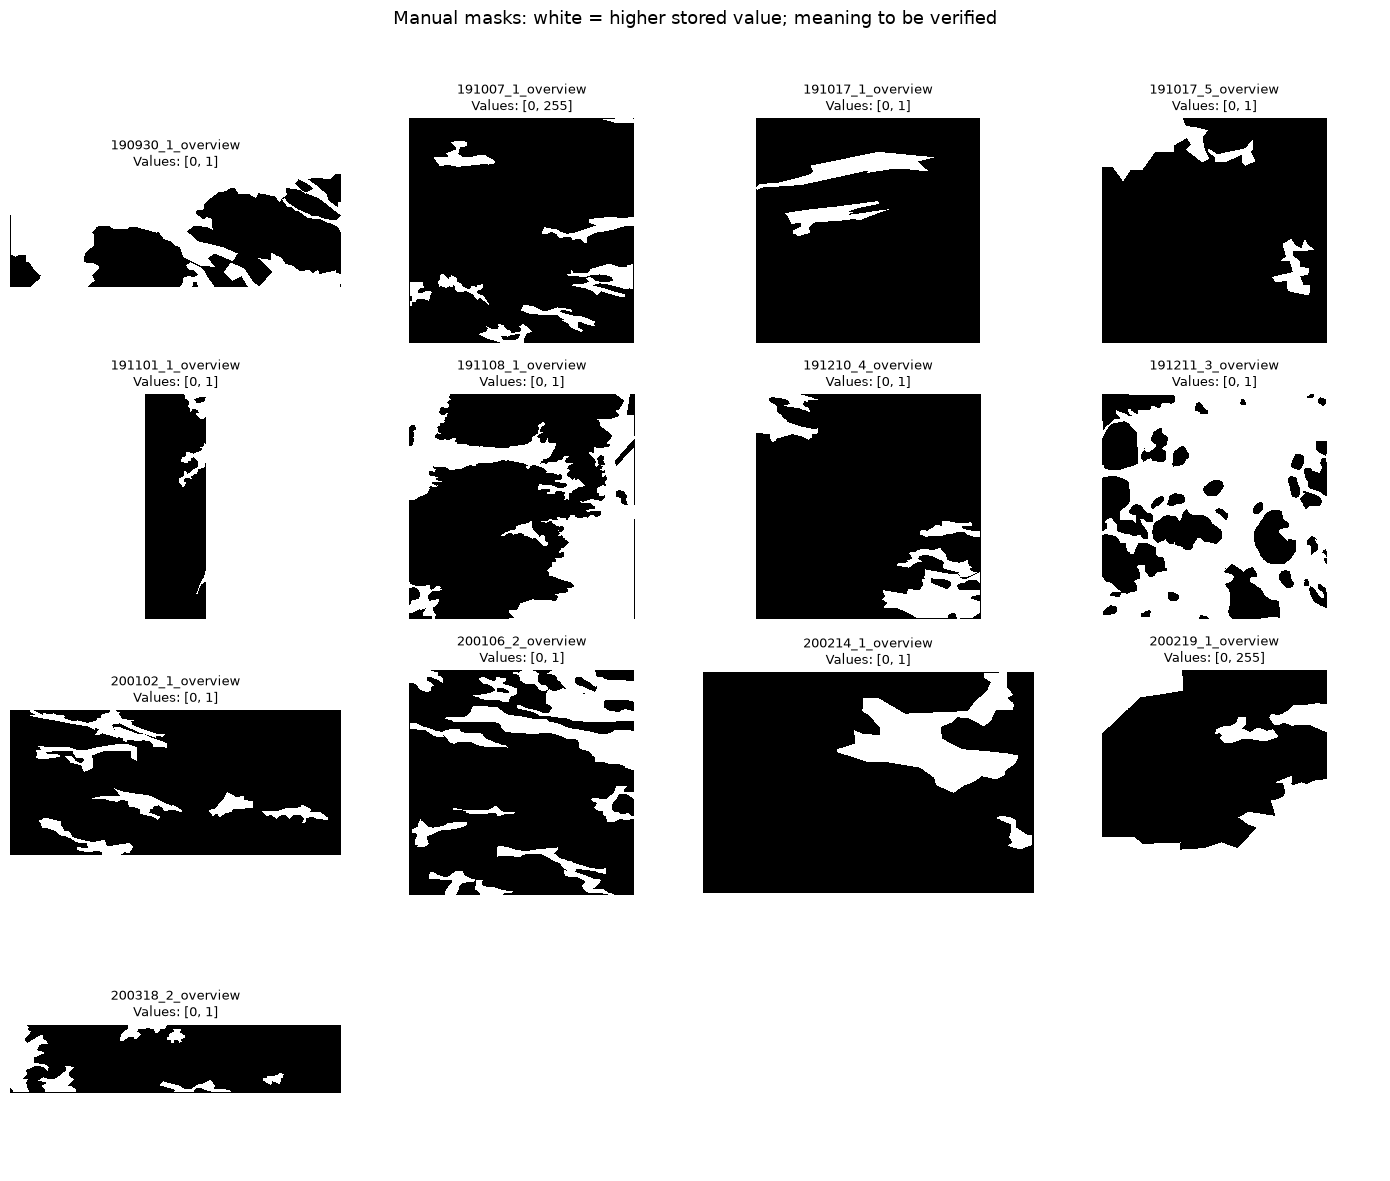

Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\outputs\figures\mask_inventory_gallery.png


In [8]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(
    axes.flat,
    mask_inventory.iterrows()
):
    path = ROOT / row["mask_relative_path"]
    mask = tifffile.imread(path)

    if mask.ndim != 2:
        ax.set_title(f"{row['sample_id']}\nNot 2D — review", fontsize=9)
        continue

    # Display the actual stored range.
    ax.imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=max(1, float(mask.max())),
        interpolation="nearest",
    )

    ax.set_title(
        f"{row['sample_id']}\n"
        f"Values: {np.unique(mask).tolist()}",
        fontsize=9,
    )

    del mask

fig.suptitle(
    "Manual masks: white = higher stored value; meaning to be verified",
    fontsize=13,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

gallery_path = FIGURES / "mask_inventory_gallery.png"
fig.savefig(gallery_path, dpi=150, bbox_inches="tight")

plt.show()
print("Saved:", gallery_path)

In [9]:
encoding_rows = []

for _, row in mask_inventory.iterrows():
    mask = tifffile.imread(ROOT / row["mask_relative_path"])
    values = np.unique(mask)

    if mask.ndim != 2:
        encoding_status = "non_2d_review"
    elif np.isin(values, [0, 1]).all():
        encoding_status = "compatible_with_script_value_1"
    elif np.isin(values, [0, 255]).all() and 255 in values:
        encoding_status = "value_255_requires_review"
    else:
        encoding_status = "unexpected_values_review"

    encoding_rows.append({
        "sample_id": row["sample_id"],
        "mask_filename": row["mask_filename"],
        "stored_values": str(values.tolist()),
        "encoding_status": encoding_status,
        "pixels_equal_1": int(np.count_nonzero(mask == 1)),
        "pixels_equal_255": int(np.count_nonzero(mask == 255)),
        "foreground_meaning_confirmed": False,
    })

    del mask

encoding_review = pd.DataFrame(encoding_rows)

encoding_review.to_csv(
    TABLES / "mask_encoding_review.csv",
    index=False
)

display(encoding_review)
print("Saved:", TABLES / "mask_encoding_review.csv")

,sample_id,mask_filename,stored_values,encoding_status,pixels_equal_1,pixels_equal_255,foreground_meaning_confirmed
0,190930_1_overview,190930_1_Mask.tif,"[0, 1]",compatible_with_script_value_1,4036431,0,False
1,191007_1_overview,191007_1_Mask.tif,"[0, 255]",value_255_requires_review,0,612503,False
2,191017_1_overview,191017_1_Mask.tif,"[0, 1]",compatible_with_script_value_1,480664,0,False
3,191017_5_overview,191017_5_Mask.tif,"[0, 1]",compatible_with_script_value_1,763990,0,False
4,191101_1_overview,191101_1_Mask.tif,"[0, 1]",compatible_with_script_value_1,351610,0,False
5,191108_1_overview,191108_1_Mask.tif,"[0, 1]",compatible_with_script_value_1,2584847,0,False
6,191210_4_overview,191210_4_Mask.tif,"[0, 1]",compatible_with_script_value_1,803173,0,False
7,191211_3_overview,191211_3_Mask.tif,"[0, 1]",compatible_with_script_value_1,4801745,0,False
8,200102_1_overview,200102_1_Mask.tif,"[0, 1]",compatible_with_script_value_1,804474,0,False
9,200106_2_overview,200106_2_Mask.tif,"[0, 1]",compatible_with_script_value_1,1642590,0,False


Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\mask_encoding_review.csv


In [10]:
mask_matching = pd.read_csv(TABLES / "mask_matching.csv")

display(mask_matching[[
    "sample_id",
    "study_group",
    "mask_available",
    "mask_width_px",
    "mask_height_px",
    "expected_crop_width_px",
    "expected_crop_height_px",
    "dimension_check",
]])

print("\nDimension-check summary:")
print(mask_matching["dimension_check"].value_counts())

print("\nSamples needing dimension review:")
display(
    mask_matching.loc[
        mask_matching["dimension_check"] == "dimension_mismatch_review",
        [
            "sample_id",
            "mask_width_px",
            "mask_height_px",
            "expected_crop_width_px",
            "expected_crop_height_px",
        ],
    ]
)

,sample_id,study_group,mask_available,mask_width_px,mask_height_px,expected_crop_width_px,expected_crop_height_px,dimension_check
0,190913_1_overview,Unlisted,False,NaN,NaN,664.0,664.0,no_mask
1,190930_1_overview,HF,True,4628.0,1583.0,4628.0,1583.0,matches_expected_roi_crop
2,191007_1_overview,HF,True,2640.0,2640.0,2640.0,2640.0,matches_expected_roi_crop
3,191007_2_overview,HF,False,NaN,NaN,3434.0,1980.0,no_mask
4,191017_1_overview,HF,True,2644.0,2648.0,2644.0,2648.0,matches_expected_roi_crop
5,191017_5_overview,HF,True,2640.0,2641.0,2640.0,2641.0,matches_expected_roi_crop
6,191101_1_overview,HF,True,1321.0,4882.0,1321.0,4882.0,matches_expected_roi_crop
7,191107_2_overview,HF,False,NaN,NaN,2331.0,1936.0,no_mask
8,191108_1_overview,HF,True,2653.0,2648.0,2653.0,2648.0,matches_expected_roi_crop
9,191114_3_overview,Donor,False,NaN,NaN,2640.0,2640.0,no_mask



Dimension-check summary:
dimension_check
matches_expected_roi_crop    13
no_mask                       9
Name: count, dtype: int64

Samples needing dimension review:


,sample_id,mask_width_px,mask_height_px,expected_crop_width_px,expected_crop_height_px


In [11]:
lif_files = sorted(
    path
    for path in ROOT.rglob("*")
    if path.is_file()
    and path.suffix.lower() == ".lif"
    and not path.name.startswith("._")
    and "__MACOSX" not in path.parts
)

native_image_index = pd.DataFrame(
    [
        {
            "sample_id": path.stem,
            "image_relative_path": str(path.relative_to(ROOT)),
            "file_size_mb": round(path.stat().st_size / 1024**2, 2),
        }
        for path in lif_files
    ],
    columns=["sample_id", "image_relative_path", "file_size_mb"],
)

display(native_image_index)
print("Native LIF files found:", len(native_image_index))

native_image_index.to_csv(
    TABLES / "native_image_index.csv",
    index=False,
)

if native_image_index.empty:
    print(
        "\nOriginal .lif files are needed for image alignment and fibrosis "
        "calculations. PNG previews cannot replace them."
    )
elif native_image_index["sample_id"].duplicated().any():
    print("\nDuplicate image IDs found; resolve before matching image paths.")

,sample_id,image_relative_path,file_size_mb


Native LIF files found: 0

Original .lif files are needed for image alignment and fibrosis calculations. PNG previews cannot replace them.


In [12]:
from scipy import ndimage

mask_inventory = pd.read_csv(TABLES / "mask_inventory.csv")
mask_matching = pd.read_csv(TABLES / "mask_matching.csv")

statistics_rows = []

for _, row in mask_inventory.iterrows():
    # Support paths saved with Windows or Unix separators.
    relative_path = str(row["mask_relative_path"]).replace("\\", "/")
    mask = tifffile.imread(ROOT / relative_path)

    if mask.ndim != 2:
        raise ValueError(
            f"{row['mask_filename']} is not 2D: {mask.shape}"
        )

    values = np.unique(mask)

    if not np.isfinite(mask).all():
        raise ValueError(f"Non-finite values in {row['mask_filename']}")

    if not (
        np.isin(values, [0, 1]).all()
        or np.isin(values, [0, 255]).all()
    ):
        raise ValueError(
            f"Unexpected encoding in {row['mask_filename']}: {values}"
        )

    # Descriptive assumption only; originals remain unchanged.
    nonzero_mask = mask != 0

    labels, component_count = ndimage.label(
        nonzero_mask,
        structure=np.ones((3, 3), dtype=int),
    )

    component_sizes = np.bincount(labels.ravel())[1:]

    total_pixels = mask.size
    nonzero_pixels = int(nonzero_mask.sum())

    statistics_rows.append({
        "sample_id": row["sample_id"],
        "mask_filename": row["mask_filename"],
        "height_px": mask.shape[0],
        "width_px": mask.shape[1],
        "stored_values": str(values.tolist()),
        "total_pixels": total_pixels,
        "nonzero_pixels": nonzero_pixels,
        "stored_nonzero_coverage_pct": 100 * nonzero_pixels / total_pixels,
        "script_value_1_coverage_pct": 100 * np.count_nonzero(mask == 1) / total_pixels,
        "connected_component_count": component_count,
        "mean_component_area_px": (
            float(component_sizes.mean()) if component_count else np.nan
        ),
        "median_component_area_px": (
            float(np.median(component_sizes)) if component_count else np.nan
        ),
        "largest_component_area_px": (
            int(component_sizes.max()) if component_count else 0
        ),
        "connectivity": 8,
        "encoding_review_required": bool(255 in values),
        "biological_foreground_verified": False,
        "native_alignment_verified": False,
    })

    del mask, nonzero_mask, labels

mask_statistics = pd.DataFrame(statistics_rows)

# Add study metadata without dropping any masks.
mask_statistics = mask_statistics.merge(
    mask_matching[[
        "sample_id",
        "included_in_study",
        "study_group",
        "dimension_check",
    ]],
    on="sample_id",
    how="left",
    validate="one_to_one",
)

mask_statistics.to_csv(
    TABLES / "mask_statistics.csv",
    index=False,
)

display(mask_statistics[[
    "sample_id",
    "stored_values",
    "stored_nonzero_coverage_pct",
    "script_value_1_coverage_pct",
    "connected_component_count",
    "encoding_review_required",
]])

print("Saved:", TABLES / "mask_statistics.csv")

,sample_id,stored_values,stored_nonzero_coverage_pct,script_value_1_coverage_pct,connected_component_count,encoding_review_required
0,190930_1_overview,"[0, 1]",55.096406,55.096406,4,False
1,191007_1_overview,"[0, 255]",8.788209,0.000000,8,True
2,191017_1_overview,"[0, 1]",6.865342,6.865342,2,False
3,191017_5_overview,"[0, 1]",10.957598,10.957598,3,False
4,191101_1_overview,"[0, 1]",5.452060,5.452060,3,False
5,191108_1_overview,"[0, 1]",36.794221,36.794221,4,False
6,191210_4_overview,"[0, 1]",11.523947,11.523947,3,False
7,191211_3_overview,"[0, 1]",68.895561,68.895561,4,False
8,200102_1_overview,"[0, 1]",10.222760,10.222760,6,False
9,200106_2_overview,"[0, 1]",23.567924,23.567924,13,False


Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\mask_statistics.csv


Two things to keep flagged:
- 191007_1_overview and 200219_1_overview use 0/255. Their nonzero coverage is 8.79% and 39.91%, respectively, but the original script’s mask == 1 selects no pixels in either file.
- 191211_3_overview has four connected regions, with one containing almost all nonzero pixels. Its median component area of 12.5 pixels is therefore plausible—it reflects three tiny regions alongside one very large region. Don’t remove those regions without a reason.

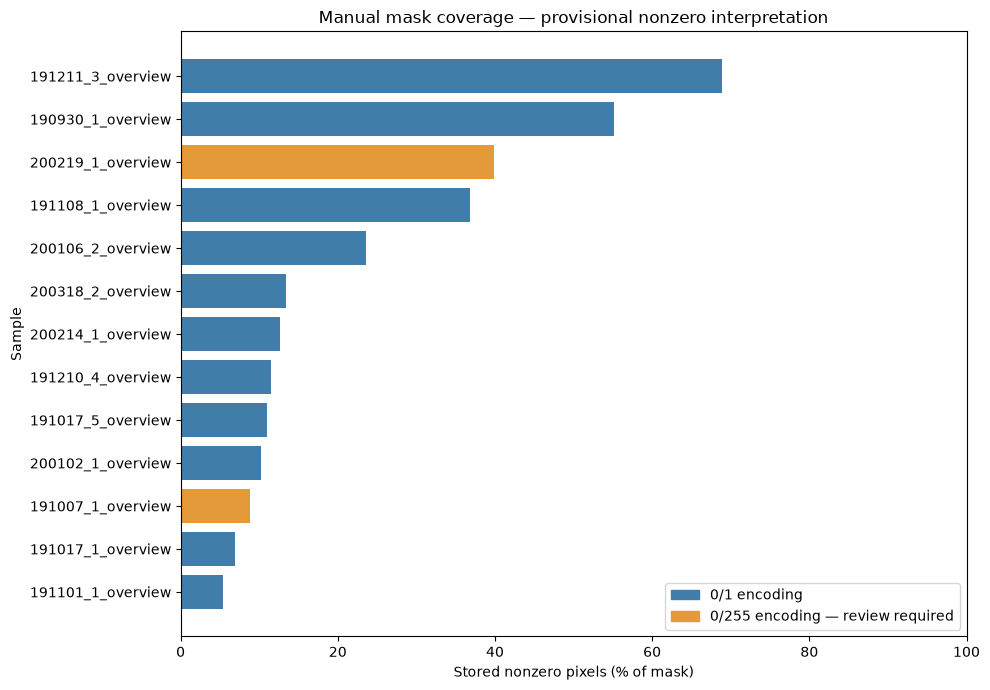

In [13]:
plot_data = mask_statistics.sort_values(
    "stored_nonzero_coverage_pct"
)

colors = [
    "#E49A38" if needs_review else "#407DA8"
    for needs_review in plot_data["encoding_review_required"]
]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data["sample_id"],
    plot_data["stored_nonzero_coverage_pct"],
    color=colors,
)

ax.set_xlabel("Stored nonzero pixels (% of mask)")
ax.set_ylabel("Sample")
ax.set_title("Manual mask coverage — provisional nonzero interpretation")
ax.set_xlim(0, 100)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#407DA8", label="0/1 encoding"),
        Patch(color="#E49A38", label="0/255 encoding — review required"),
    ],
    loc="lower right",
)

fig.tight_layout()
fig.savefig(
    FIGURES / "mask_coverage_by_sample.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

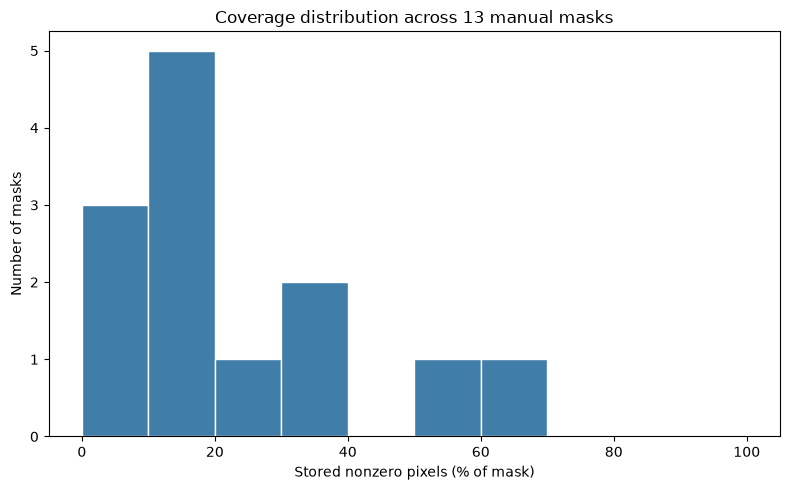

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    mask_statistics["stored_nonzero_coverage_pct"],
    bins=np.linspace(0, 100, 11),
    color="#407DA8",
    edgecolor="white",
)

ax.set_xlabel("Stored nonzero pixels (% of mask)")
ax.set_ylabel("Number of masks")
ax.set_title("Coverage distribution across 13 manual masks")

fig.tight_layout()
fig.savefig(
    FIGURES / "mask_coverage_distribution.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

In [15]:
coverage = mask_statistics["stored_nonzero_coverage_pct"]

summary = pd.DataFrame({
    "measurement": [
        "Number of masks",
        "Mean stored nonzero coverage (%)",
        "Median stored nonzero coverage (%)",
        "Minimum stored nonzero coverage (%)",
        "Maximum stored nonzero coverage (%)",
        "Masks requiring encoding review",
    ],
    "value": [
        len(mask_statistics),
        coverage.mean(),
        coverage.median(),
        coverage.min(),
        coverage.max(),
        int(mask_statistics["encoding_review_required"].sum()),
    ],
})

display(summary)

summary.to_csv(TABLES / "mask_summary.csv", index=False)

notes = """# Mask-only EDA: methods and limitations

- Original TIFF masks were read without alteration.
- All available masks were matched to sample IDs and expected ROI crop dimensions.
- Coverage was calculated as nonzero pixels divided by total mask pixels.
- This is a descriptive stored-value measurement, not fibrosis percentage.
- Two masks use 0/255 encoding: 191007_1_overview and 200219_1_overview.
- The original MATLAB script selects manual-mask pixels using mask == 1.
  It therefore does not select the 255-valued pixels in those two files.
- Nonzero interpretation of the 0/255 masks remains provisional.
- Connected components use 8-neighbor connectivity; no size filtering was applied.
- Component areas are reported in pixels, not physical units.
- Matching crop dimensions does not establish anatomical alignment.
- Native microscopy alignment and WGA thresholding have not been performed.
- All 13 available masks belong to HF samples according to the supplied study mapping.
- Missing masks, including donor masks, do not indicate zero fibrosis.
- No healthy-versus-HF fibrosis comparison can be made from these masks alone.
"""

notes_path = DOCS / "mask_only_eda_notes.md"
notes_path.write_text(notes, encoding="utf-8")

print("Saved:", TABLES / "mask_summary.csv")
print("Saved:", notes_path)

,measurement,value
0,Number of masks,13.000000
1,Mean stored nonzero coverage (%),23.386958
2,Median stored nonzero coverage (%),12.600885
3,Minimum stored nonzero coverage (%),5.452060
4,Maximum stored nonzero coverage (%),68.895561
5,Masks requiring encoding review,2.000000


Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\mask_summary.csv
Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\docs\mask_only_eda_notes.md


Across 13 available manual masks, stored nonzero coverage ranged from 5.45% to 68.90%, with a median of 12.60%. All masks matched the expected ROI crop dimensions. Two masks used a different pixel encoding and require review. These preliminary measurements describe mask coverage; fibrosis quantification remains pending native-image alignment and WGA analysis.

## Mask-only EDA findings and limitations

The dataset README identifies the 13 supplied masks as binary manual
segmentations of non-myocyte regions. These regions supplement
thresholded WGA signals in the original fibrosis analysis.

All 13 masks loaded successfully and matched the expected ROI crop
dimensions. Stored nonzero coverage ranged from 5.45% to 68.90%, with
a median of 12.60%.

Eleven masks use 0/1 encoding. Two masks—191007_1_overview and
200219_1_overview—use 0/255 encoding. The README does not specify
foreground polarity or encoding, while the MATLAB script explicitly
selects pixels equal to 1. These differences remain flagged for review.

Coverage calculations describe stored nonzero pixels, not validated
fibrosis percentages. Matching dimensions does not establish anatomical
alignment. Native-image alignment and WGA analysis remain pending.

All available masks correspond to HF samples according to the supplied
study mapping. Missing donor masks do not imply zero fibrosis, and these
mask-only results cannot support a healthy-versus-HF fibrosis comparison.

In [16]:
from readlif.reader import LifFile

SAMPLE_ID = "190930_1_overview"
LIF_PATH = ROOT / "Images" / f"{SAMPLE_ID}.lif"

if not LIF_PATH.is_file():
    raise FileNotFoundError(f"Image not found: {LIF_PATH}")

print("File found:", LIF_PATH.name)
print(f"File size: {LIF_PATH.stat().st_size / 1024**3:.2f} GiB")

lif = LifFile(str(LIF_PATH))

series_rows = []

for series_index, image in enumerate(lif.get_iter_image()):
    series_rows.append({
        "sample_id": SAMPLE_ID,
        "series_index": series_index,
        "series_name": image.name,
        "width_px": image.dims.x,
        "height_px": image.dims.y,
        "channel_count": image.channels,
        "z_slices": image.dims.z,
        "timepoints": image.dims.t,
    })

native_series = pd.DataFrame(series_rows)
display(native_series)

# Update the native-image index without removing other indexed samples.
index_path = TABLES / "native_image_index.csv"

existing_index = (
    pd.read_csv(index_path)
    if index_path.exists()
    else pd.DataFrame(
        columns=["sample_id", "image_relative_path", "file_size_mb"]
    )
)

existing_index = existing_index.loc[
    existing_index["sample_id"] != SAMPLE_ID
]

new_entry = pd.DataFrame([{
    "sample_id": SAMPLE_ID,
    "image_relative_path": LIF_PATH.relative_to(ROOT).as_posix(),
    "file_size_mb": round(LIF_PATH.stat().st_size / 1024**2, 2),
}])

native_image_index = pd.concat(
    [existing_index, new_entry],
    ignore_index=True,
)

native_image_index.to_csv(index_path, index=False)

print("Saved updated native_image_index.csv")

File found: 190930_1_overview.lif
File size: 1.59 GiB


,sample_id,series_index,series_name,width_px,height_px,channel_count,z_slices,timepoints
0,190930_1_overview,0,TileScan 001/TileScan_001_Merging,15525,10968,5,1,1


Saved updated native_image_index.csv


In [17]:
from readlif.reader import LifFile
import gc

SAMPLE_ID = "190930_1_overview"
LIF_PATH = ROOT / "Images" / f"{SAMPLE_ID}.lif"

roi_manifest = pd.read_csv(
    P2_HANDOFF / "roi_transform_manifest.csv"
)

sample_rows = roi_manifest.loc[
    roi_manifest["sample_id"] == SAMPLE_ID
]

if len(sample_rows) != 1:
    raise ValueError("Expected exactly one ROI record for this sample.")

roi_record = sample_rows.iloc[0]

angle = float(roi_record["rotation_angle_deg"])

if angle != 0:
    raise ValueError(
        "This cell is intended for the zero-angle test sample only."
    )

lif = LifFile(str(LIF_PATH))
image = lif.get_image(0)

# Assigned by fibrosisAnalysis.m; reader correspondence still needs validation.
WGA_CHANNEL_INDEX = 2

frame = image.get_frame(z=0, t=0, c=WGA_CHANNEL_INDEX)
wga_native = np.asarray(frame).copy()

print("Sample:", SAMPLE_ID)
print("WGA channel index:", WGA_CHANNEL_INDEX)
print("Native shape:", wga_native.shape)
print("Native dtype:", wga_native.dtype)
print("Intensity range:", wga_native.min(), "to", wga_native.max())

assert wga_native.shape == (10968, 15525)

del frame, image, lif
gc.collect()

Sample: 190930_1_overview
WGA channel index: 2
Native shape: (10968, 15525)
Native dtype: uint16
Intensity range: 0 to 150


87

In [18]:
# Original sequence: vertical flip, then clockwise 90° rotation.
wga_transformed = np.rot90(
    np.flipud(wga_native),
    k=-1,
)

# Check that coordinates are finite integers.
coordinate_names = ["x1", "x2", "y1", "y3"]
coordinates = {}

for name in coordinate_names:
    value = float(roi_record[name])

    if not np.isfinite(value) or not value.is_integer():
        raise ValueError(f"Invalid coordinate {name}: {value}")

    coordinates[name] = int(value)

x1 = coordinates["x1"]
x2 = coordinates["x2"]
y1 = coordinates["y1"]
y3 = coordinates["y3"]

height, width = wga_transformed.shape

if not (1 <= x1 < x2 <= width + 1):
    raise ValueError("ROI x coordinates are outside the transformed image.")

if not (1 <= y1 < y3 <= height + 1):
    raise ValueError("ROI y coordinates are outside the transformed image.")

# MATLAB subtracts 1 from upper endpoints before inclusive indexing.
# Equivalent Python slices:
wga_roi = wga_transformed[
    y1 - 1:y3 - 1,
    x1 - 1:x2 - 1,
].copy()

manual_mask_path = MASK_DIR / "190930_1_Mask.tif"
manual_mask = tifffile.imread(manual_mask_path)

print("Transformed image shape:", wga_transformed.shape)
print("WGA ROI shape:", wga_roi.shape)
print("Manual mask shape:", manual_mask.shape)
print("Manual mask values:", np.unique(manual_mask))

assert wga_roi.shape == manual_mask.shape, "ROI and mask dimensions differ."
assert np.isin(manual_mask, [0, 1]).all(), "Unexpected mask encoding."

print("\nDimensions match. Visual alignment still needs review.")

Transformed image shape: (15525, 10968)
WGA ROI shape: (1583, 4628)
Manual mask shape: (1583, 4628)
Manual mask values: [0 1]

Dimensions match. Visual alignment still needs review.


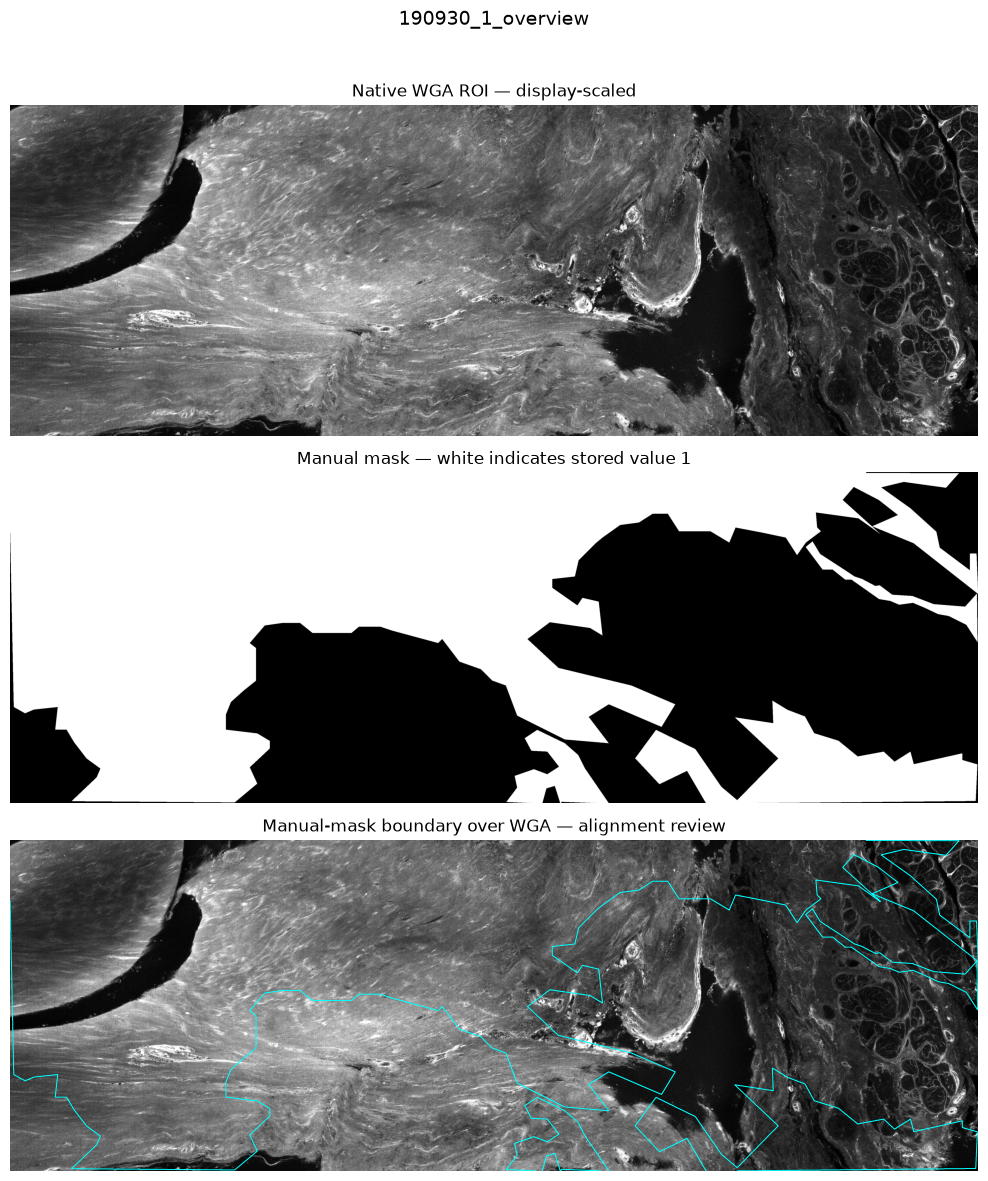

Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\outputs\mask_overlays\190930_1_overview_wga_mask_alignment.png


In [20]:
# Display scaling only.
display_low, display_high = np.percentile(wga_roi, [1, 99.5])

if display_high <= display_low:
    display_low = float(wga_roi.min())
    display_high = float(wga_roi.max())

if display_high <= display_low:
    display_high = display_low + 1

fig, axes = plt.subplots(3, 1, figsize=(15, 12))

axes[0].imshow(
    wga_roi,
    cmap="gray",
    vmin=display_low,
    vmax=display_high,
)
axes[0].set_title("Native WGA ROI — display-scaled")

axes[1].imshow(
    manual_mask,
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Manual mask — white indicates stored value 1")

axes[2].imshow(
    wga_roi,
    cmap="gray",
    vmin=display_low,
    vmax=display_high,
)
axes[2].contour(
    manual_mask == 1,
    levels=[0.5],
    colors=["cyan"],
    linewidths=0.7,
)
axes[2].set_title(
    "Manual-mask boundary over WGA — alignment review"
)

for ax in axes:
    ax.axis("off")

fig.suptitle(SAMPLE_ID, fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96])

overlay_path = OVERLAYS / f"{SAMPLE_ID}_wga_mask_alignment.png"
fig.savefig(overlay_path, dpi=160, bbox_inches="tight")

plt.show()
print("Saved:", overlay_path)

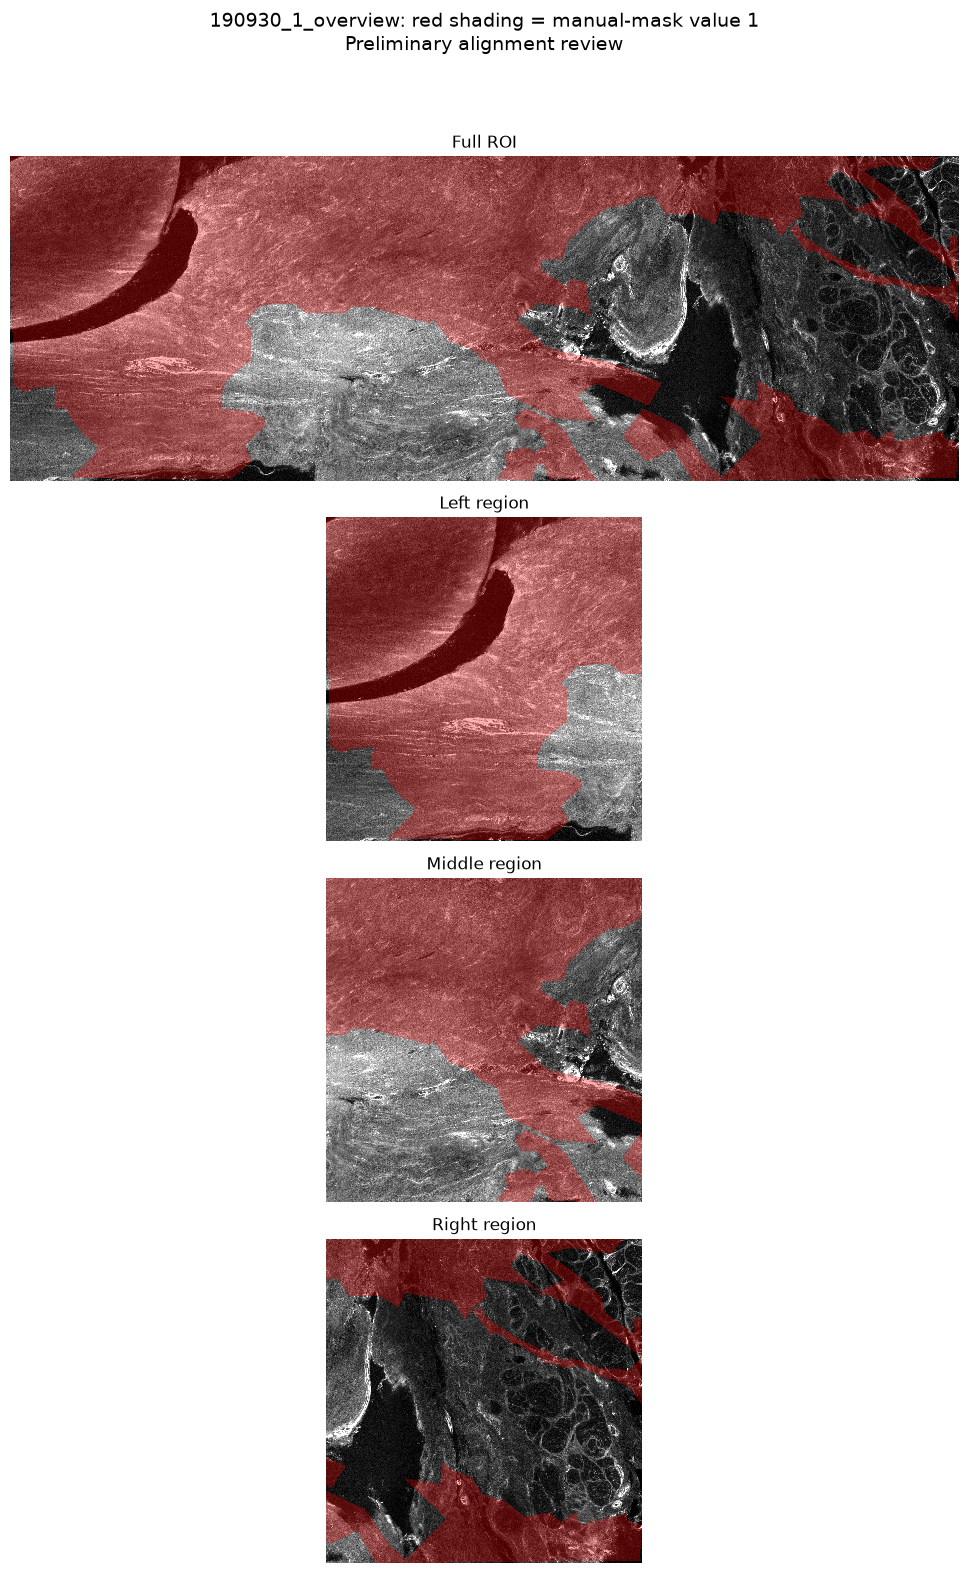

Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\outputs\mask_overlays\190930_1_overview_mask_shaded_review.png
Selected manual-mask coverage: 55.10%


In [21]:
# Highlight the exact pixels selected by the original MATLAB script.
selected = manual_mask == 1

# Red shading shows selected manual-mask regions.
highlight = np.zeros((*selected.shape, 4), dtype=np.float32)
highlight[..., 0] = 1.0
highlight[..., 3] = selected.astype(np.float32) * 0.30

height, width = wga_roi.shape

regions = [
    ("Full ROI", 0, width, 0, height),
    ("Left region", 0, width // 3, 0, height),
    ("Middle region", width // 3, 2 * width // 3, 0, height),
    ("Right region", 2 * width // 3, width, 0, height),
]

fig, axes = plt.subplots(4, 1, figsize=(16, 16))

for ax, (title, left, right, top, bottom) in zip(axes, regions):
    image_crop = wga_roi[top:bottom, left:right]
    highlight_crop = highlight[top:bottom, left:right]

    ax.imshow(
        image_crop,
        cmap="gray",
        vmin=display_low,
        vmax=display_high,
        interpolation="nearest",
    )

    ax.imshow(
        highlight_crop,
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"{SAMPLE_ID}: red shading = manual-mask value 1\n"
    "Preliminary alignment review",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

review_path = OVERLAYS / f"{SAMPLE_ID}_mask_shaded_review.png"
fig.savefig(review_path, dpi=180, bbox_inches="tight")

plt.show()
print("Saved:", review_path)
print(f"Selected manual-mask coverage: {selected.mean() * 100:.2f}%")

In [22]:
loader_files = [
    path
    for path in ROOT.rglob("*")
    if path.is_file() and path.name.lower() == "ci_loadlif.m"
]

if loader_files:
    for path in loader_files:
        print(path)
else:
    print(
        "ci_loadLif.m was not found in the project. "
        "The original loader's orientation convention remains unconfirmed."
    )

ci_loadLif.m was not found in the project. The original loader's orientation convention remains unconfirmed.


In [23]:
alignment_review = pd.DataFrame([{
    "sample_id": SAMPLE_ID,
    "series_index": 0,
    "python_channel_index": WGA_CHANNEL_INDEX,
    "channel_assignment_source": "fibrosisAnalysis.m",
    "roi_height_px": wga_roi.shape[0],
    "roi_width_px": wga_roi.shape[1],
    "mask_dimensions_match": wga_roi.shape == manual_mask.shape,
    "manual_mask_coverage_pct": float((manual_mask == 1).mean() * 100),
    "alignment_status": "needs_reference_validation",
    "native_alignment_verified": False,
    "review_notes": (
        "Dimensions match. Shaded overlay includes portions of dark gaps "
        "and crosses visible tissue structures. Original MATLAB loader "
        "orientation and reference crop have not been confirmed. "
        "No corrective mask transformations applied."
    ),
}])

review_csv = TABLES / "native_alignment_review.csv"
alignment_review.to_csv(review_csv, index=False)

display(alignment_review)
print("Saved:", review_csv)

,sample_id,series_index,python_channel_index,channel_assignment_source,roi_height_px,roi_width_px,mask_dimensions_match,manual_mask_coverage_pct,alignment_status,native_alignment_verified,review_notes
0,190930_1_overview,0,2,fibrosisAnalysis.m,1583,4628,True,55.096406,needs_reference_validation,False,Dimensions match. Shaded overlay includes port...


Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\data\processed\native_alignment_review.csv


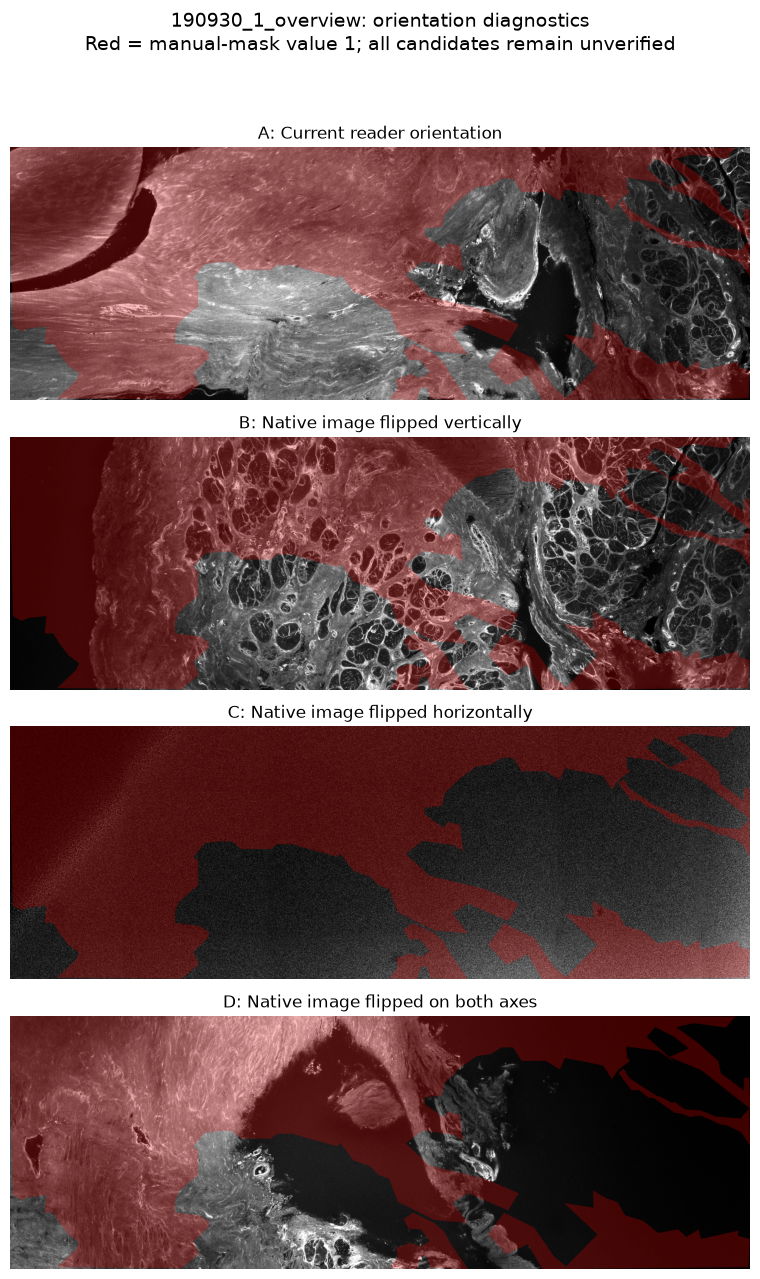

Saved: c:\Users\mmsr4\D37-Semantic-Data-Lake\Person3_Masks_Fibrosis\outputs\mask_overlays\190930_1_overview_orientation_candidates.png


In [24]:
# Diagnostic only: compare possible native-reader orientation differences.
# Do not select a candidate or calculate validated fibrosis from this figure.

starting_orientations = [
    ("A: Current reader orientation", wga_native),
    ("B: Native image flipped vertically", np.flipud(wga_native)),
    ("C: Native image flipped horizontally", np.fliplr(wga_native)),
    ("D: Native image flipped on both axes", wga_native[::-1, ::-1]),
]

assert angle == 0, "This diagnostic is only for the current zero-angle sample."

selected = manual_mask == 1

highlight = np.zeros((*selected.shape, 4), dtype=np.float32)
highlight[..., 0] = 1
highlight[..., 3] = selected.astype(np.float32) * 0.25

fig, axes = plt.subplots(4, 1, figsize=(16, 13))

for ax, (title, starting_image) in zip(axes, starting_orientations):
    # Apply the same documented geometric operations to each candidate.
    transformed = np.rot90(np.flipud(starting_image), k=-1)

    candidate_roi = transformed[
        y1 - 1:y3 - 1,
        x1 - 1:x2 - 1,
    ]

    if candidate_roi.shape != manual_mask.shape:
        raise ValueError(f"Unexpected crop shape for {title}")

    low, high = np.percentile(candidate_roi, [1, 99.5])

    if high <= low:
        high = low + 1

    ax.imshow(
        candidate_roi,
        cmap="gray",
        vmin=low,
        vmax=high,
    )
    ax.imshow(highlight)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"{SAMPLE_ID}: orientation diagnostics\n"
    "Red = manual-mask value 1; all candidates remain unverified",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

comparison_path = OVERLAYS / f"{SAMPLE_ID}_orientation_candidates.png"
fig.savefig(comparison_path, dpi=160, bbox_inches="tight")

plt.show()
print("Saved:", comparison_path)

In [25]:
# Provisional calculation only.
# Uses candidate A and does not approve its alignment.

wga_values = np.asarray(wga_roi, dtype=np.float64)

assert wga_values.shape == manual_mask.shape
assert np.isfinite(wga_values).all()
assert np.isin(manual_mask, [0, 1]).all()

# MATLAB mode: smallest value wins if frequencies tie.
unique_values, frequencies = np.unique(
    wga_values,
    return_counts=True,
)

roi_mode = float(unique_values[np.argmax(frequencies)])

# Match MATLAB's default sample standard deviation.
roi_sd = float(wga_values.std(ddof=1))
threshold = roi_mode + roi_sd

wga_binary = wga_values >= threshold
manual_binary = manual_mask == 1

combined_binary = wga_binary | manual_binary
added_by_manual = manual_binary & ~wga_binary

provisional_result = pd.DataFrame([{
    "sample_id": SAMPLE_ID,
    "orientation_candidate": "A_documented_starting_workflow",
    "threshold_method": "ROI mode + sample standard deviation",
    "roi_mode": roi_mode,
    "roi_sample_sd": roi_sd,
    "threshold": threshold,
    "analyzed_roi_pixels": wga_values.size,
    "wga_threshold_area_pct": float(wga_binary.mean() * 100),
    "manual_mask_coverage_pct": float(manual_binary.mean() * 100),
    "manual_added_area_percentage_points": float(
        added_by_manual.mean() * 100
    ),
    "provisional_combined_area_pct": float(
        combined_binary.mean() * 100
    ),
    "native_alignment_verified": False,
    "measurement_status": "provisional_alignment_unresolved",
}])

# Sanity checks for the union operation.
assert combined_binary.sum() >= wga_binary.sum()
assert combined_binary.sum() >= manual_binary.sum()

provisional_result.to_csv(
    TABLES / "provisional_fibrosis_pipeline_check.csv",
    index=False,
)

display(provisional_result.T)

,0
sample_id,190930_1_overview
orientation_candidate,A_documented_starting_workflow
threshold_method,ROI mode + sample standard deviation
roi_mode,29.0
roi_sample_sd,14.44572
threshold,43.44572
analyzed_roi_pixels,7326124
wga_threshold_area_pct,11.294799
manual_mask_coverage_pct,55.096406
manual_added_area_percentage_points,48.927673


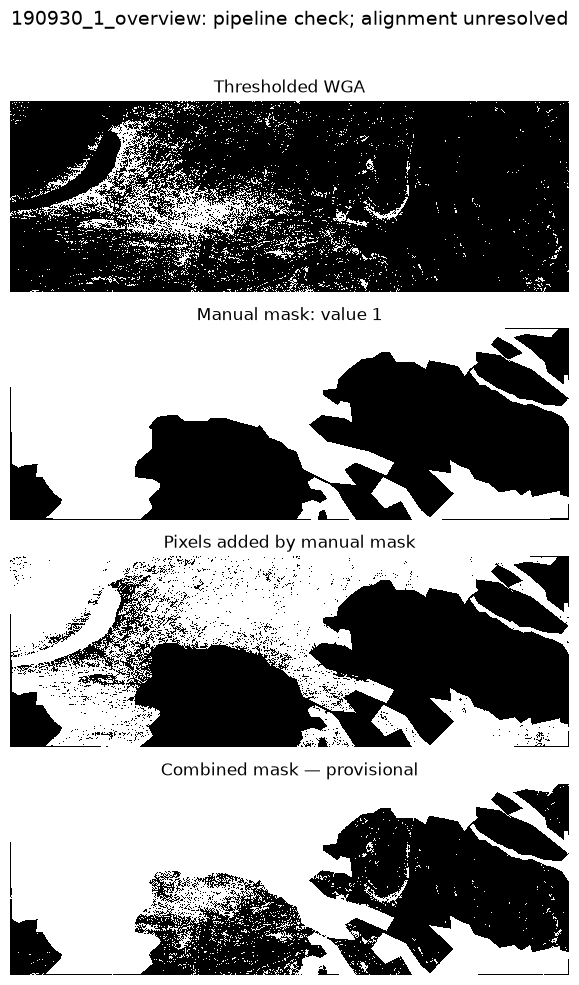

In [26]:
panels = [
    ("Thresholded WGA", wga_binary),
    ("Manual mask: value 1", manual_binary),
    ("Pixels added by manual mask", added_by_manual),
    ("Combined mask — provisional", combined_binary),
]

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

for ax, (title, array) in zip(axes, panels):
    ax.imshow(
        array,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"{SAMPLE_ID}: pipeline check; alignment unresolved",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    FIGURES / f"{SAMPLE_ID}_provisional_thresholding.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()